# Étape 2 — Transformation et préparation des données

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("maqdadali/mental-health-risk-prediction-dataset-students")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'mental-health-risk-prediction-dataset-students' dataset.
Path to dataset files: /kaggle/input/mental-health-risk-prediction-dataset-students


In [3]:
import shutil

shutil.copytree(
    path,
    "data/raw",
    dirs_exist_ok=True
)

print("Dataset copié dans data/raw/")

Dataset copié dans data/raw/


In [4]:
import glob

csv_files = glob.glob("data/raw/**/*.csv", recursive=True)


In [5]:
import pandas as pd

df = pd.read_csv("data/raw/student_mental_health.csv")

df.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [6]:
X = df.drop(columns=["Mental_Health_Risk", "Student_ID"])

y = df["Mental_Health_Risk"]

In [7]:
#Diviser les données en deux ensembles : un ensemble d’entraînement (80 %) et un ensemble de test (20 %).
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [8]:
#Traiter les valeurs manquantes en choisissant la méthode d’imputation la plus adaptée à la nature des données
numeric_features = [
    "Age",
    "Year_of_Study",
    "Sleep_Hours",
    "Study_Hours_Per_Week",
    "GPA",
    "Social_Media_Hours",
    "Screen_Time_Hours",
    "Financial_Stress",
    "Family_Support",
    "Attendance_Rate"
]

categorical_features = [
    "Gender",
    "Physical_Activity",
    "Part_Time_Job",
    "Diet_Quality",
    "Previous_Mental_Health_History"
]

In [9]:

from sklearn.impute import SimpleImputer

imputer_numeric = SimpleImputer(strategy="median")


In [10]:
imputer_categoriel =SimpleImputer(strategy="most_frequent")

In [11]:
#Détecter et traiter les valeurs aberrantes en utilisant une méthode appropriée IQR
for col in numeric_features:
    Q1 =X_train[col].quantile(0.25)
    Q3 =X_test[col].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    Upper =Q3 + 1.5 * IQR
    
    outliers = X_train[
        (X_train[col] < lower) |
        (X_train[col] > Upper)
    ]
    
    print(f"{col} :   {len(outliers)} valeurs aberrantes")

Age :   42 valeurs aberrantes
Year_of_Study :   0 valeurs aberrantes
Sleep_Hours :   1 valeurs aberrantes
Study_Hours_Per_Week :   8 valeurs aberrantes
GPA :   11 valeurs aberrantes
Social_Media_Hours :   16 valeurs aberrantes
Screen_Time_Hours :   11 valeurs aberrantes
Financial_Stress :   0 valeurs aberrantes
Family_Support :   0 valeurs aberrantes
Attendance_Rate :   11 valeurs aberrantes


In [12]:
#Encoder les variables catégorielles afin de les convertir en valeurs numériques
from sklearn.preprocessing import OneHotEncoder
nominal_features = [
    "Gender",
    "Part_Time_Job",
    "Previous_Mental_Health_History"
]

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)


In [13]:
from sklearn.preprocessing import OrdinalEncoder

ordinal_features = [
    "Physical_Activity",
    "Diet_Quality"
]

ordinal_encoder =OrdinalEncoder(
    categories=[
        ["Low", "Medium", "High"],
        ["Poor", "Average", "Good"] 
    ],
    handle_unknown="use_encoded_value",
    unknown_value=-1
)


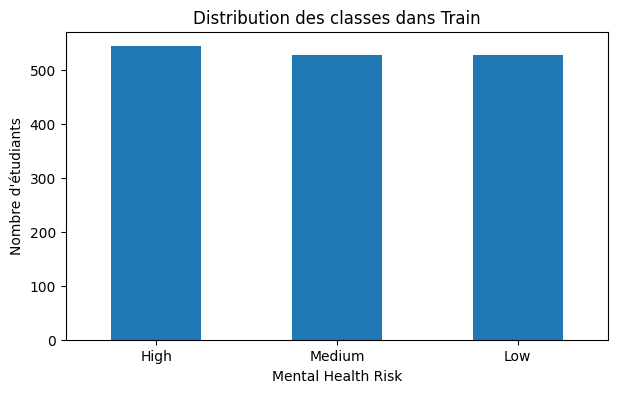

In [14]:
import matplotlib.pyplot as plt

y_train.value_counts().plot(
    kind="bar",
    figsize=(7, 4),
    title="Distribution des classes dans Train"
)

plt.xlabel("Mental Health Risk")
plt.ylabel("Nombre d'étudiants")
plt.xticks(rotation=0)
plt.show()

In [15]:
# Standardiser les variables numériques
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()


In [16]:
#Construire le preprocessing Pipeline

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Pipeline des variables numériques
def get_preprocessor():
    numeric_pipeline = Pipeline([
        ("Imputer",SimpleImputer(strategy="mean")),
        ("scaler",StandardScaler())
    ])

    # Pipeline des variables nominales
    nominal_pipeline =Pipeline([
        ("Imputer",SimpleImputer(strategy="most_frequent")),
        ("encoder",OneHotEncoder(handle_unknown="ignore",sparse_output=False))
    ])

    # Pipeline des variables ordinales
    ordinal_pipeline =Pipeline([
        ("Imputer",SimpleImputer(strategy="most_frequent")),
        ("encoder",OrdinalEncoder(
            categories=[
                ["Low", "Moderate", "High"],
                ["Poor", "Average", "Good"]
            ],
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
    ])


    preprocessor = ColumnTransformer([
        ("numeric",numeric_pipeline ,numeric_features),
        ("nominal",nominal_pipeline ,nominal_features),
        ("ordinal",ordinal_pipeline ,ordinal_features)
    ])
    return preprocessor

In [ ]:
from sklearn.pipeline import Pipeline

def get_pipeline(model, preprocessor_):
    # le pipeline complet

    pipeline_lr = Pipeline([
    ("preprocessor", preprocessor_),
    ("classifier", model)
    ])
    return pipeline_lr 

In [18]:
from sklearn.model_selection import GridSearchCV


def train_model(pipeline, params):
    

    grid_search_lr =GridSearchCV(
    estimator=pipeline,
    param_grid=params,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1,
    )
    grid_search_lr.fit(X_train, y_train)
    return grid_search_lr

# Étape 3 — Entraînement et comparaison des modèles

In [23]:
preprocessor = get_preprocessor()
X_train = preprocessor.fit_transform(X_train)

X_test = preprocessor.transform(X_test)


In [ ]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression

model_lr = Pipeline(
    ("preprocess" , preprocessor),
    ("mode" , LogisticRegression(max_iter=100))
)

model_lr.fit(X_train ,y_train)

y_pred_lr = model_lr.predict(X_test)

In [25]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test ,y_pred_lr)

print("accuracy logistic regression",accuracy)

accuracy logistic regression 0.7575


In [26]:
#Random Forest
from sklearn.ensemble import RandomForestClassifier

model_rfc =RandomForestClassifier(
    n_estimators=100,
    random_state=42,
)

model_rfc.fit(X_train,y_train)

y_pred_rfc =model_rfc.predict(X_test)

In [27]:
accuracy_rfc =accuracy_score(y_test ,y_pred_rfc)

print("accuracy random forest classifier",accuracy_rfc)

accuracy random forest classifier 0.715


In [28]:
from sklearn.neighbors import KNeighborsClassifier

model_knn =KNeighborsClassifier(n_neighbors=5)

model_knn.fit(X_train,y_train)

y_pred_knn =model_knn.predict(X_test)

In [29]:
accuracy_knn =accuracy_score(y_test ,y_pred_knn)

print("accuracy KNN",accuracy_knn)

accuracy KNN 0.5875


In [30]:
from sklearn.metrics import classification_report
predictions = {
    "KNN": y_pred_knn,
    "Random Forest": y_pred_rfc,
    "Logistic Regression": y_pred_lr
}

for name ,y_pred in predictions.items() :
    print(name ,classification_report(
        y_true=y_test ,
        y_pred=y_pred
    ))

KNN               precision    recall  f1-score   support

        High       0.66      0.69      0.67       136
         Low       0.63      0.74      0.68       132
      Medium       0.43      0.33      0.37       132

    accuracy                           0.59       400
   macro avg       0.57      0.59      0.57       400
weighted avg       0.57      0.59      0.58       400

Random Forest               precision    recall  f1-score   support

        High       0.75      0.79      0.77       136
         Low       0.80      0.78      0.79       132
      Medium       0.59      0.57      0.58       132

    accuracy                           0.71       400
   macro avg       0.71      0.71      0.71       400
weighted avg       0.71      0.71      0.71       400

Logistic Regression               precision    recall  f1-score   support

        High       0.81      0.83      0.82       136
         Low       0.82      0.80      0.81       132
      Medium       0.64      0.64    

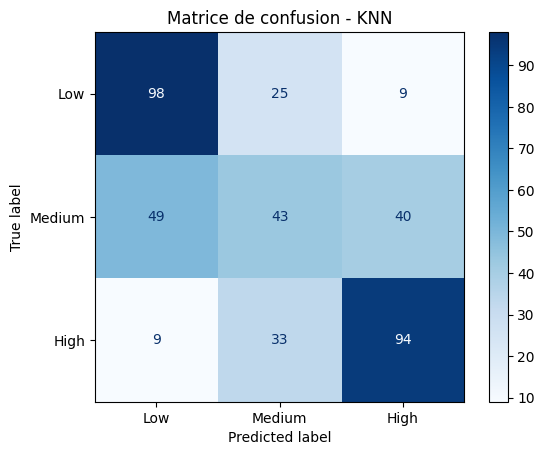

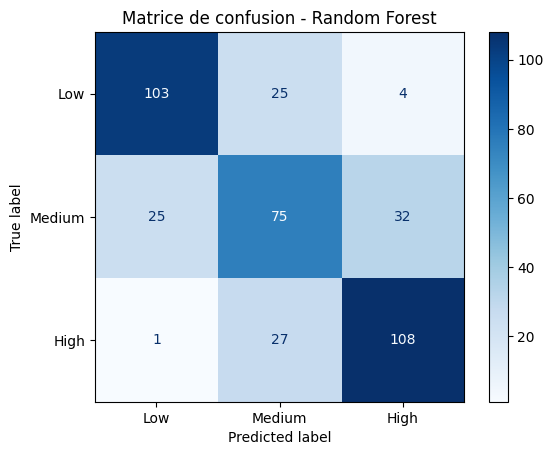

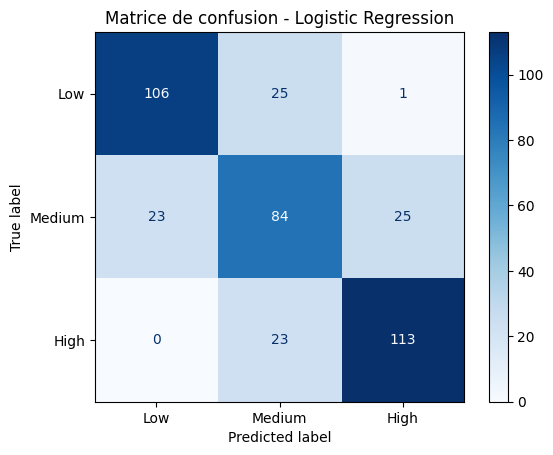

In [31]:
from sklearn.metrics import ConfusionMatrixDisplay ,confusion_matrix

import matplotlib.pyplot as plt

for name ,y_pred in predictions.items():
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=["Low", "Medium", "High"],
        display_labels=["Low", "Medium", "High"],
        cmap="Blues"
    )
    plt.title(f"Matrice de confusion - {name}")
    plt.show()


In [32]:
from sklearn.metrics import roc_auc_score

for name, model in {
    "KNN": model_knn,
    "Random Forest": model_rfc,
    "Logistic Regression": model_lr
}.items():

    y_proba = model.predict_proba(X_test)

    auc = roc_auc_score(
        y_test,
        y_proba,
        multi_class="ovr",
        average="weighted"
    )
    print(f"{name} : {auc}")


KNN : 0.7760390518995929
Random Forest : 0.8542546500452284
Logistic Regression : 0.9141383989145183


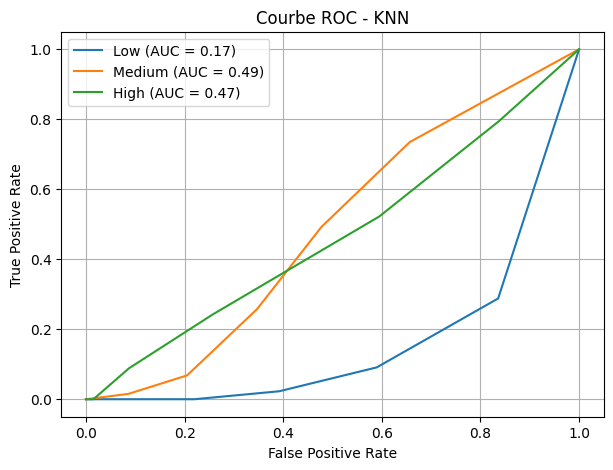

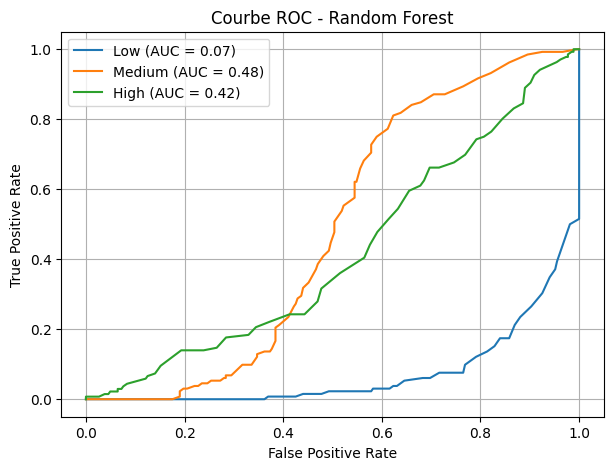

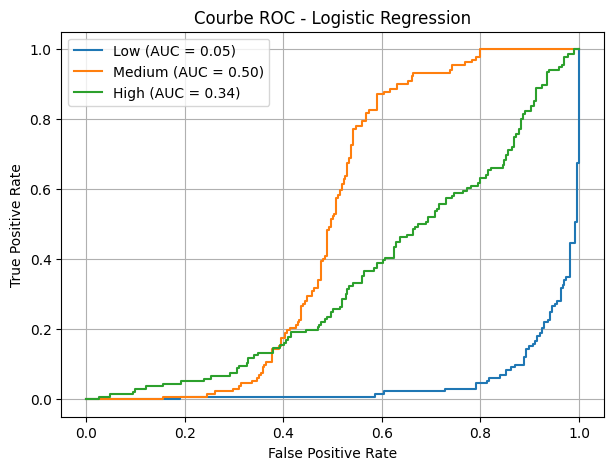

In [33]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

classes = ["Low", "Medium", "High"]

y_test_bin = label_binarize(y_test, classes=classes)

models = {
    "KNN": model_knn,
    "Random Forest": model_rfc,
    "Logistic Regression": model_lr
}

for name, model in models.items():

    y_proba = model.predict_proba(X_test)

    plt.figure(figsize=(7, 5))

    for i, class_name in enumerate(classes):

        fpr, tpr, thresholds = roc_curve(
            y_test_bin[:, i],
            y_proba[:, i]
        )

        roc_auc = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            label=f"{class_name} (AUC = {roc_auc:.2f})"
        )


    plt.title(f"Courbe ROC - {name}")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.grid()
    plt.show()

In [34]:
best_models = [model_lr ,model_rfc]

In [36]:
from sklearn.model_selection import GridSearchCV
param = {
    "C": [0.01, 0.1, 1, 10, 100]
}

grid_search_lr =GridSearchCV(
    estimator=model_lr,
    param_grid=param,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1,
)
grid_search_lr.fit(X_train, y_train)
print("Meilleurs paramètres :", grid_search_lr.best_params_)

print("Meilleur accuracy :", grid_search_lr.best_score_)

Meilleurs paramètres : {'C': 0.1}
Meilleur accuracy : 0.7479088569013665


In [37]:
params ={
    "n_estimators":[100 ,200 ,300]
}

grid_search_rfc =GridSearchCV(
    estimator=model_rfc,
    param_grid= params,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1 
)


grid_search_rfc.fit(X_train ,y_train)
print("Meilleurs paramètres :", grid_search_rfc.best_params_)

print("Meilleur accuracy :", grid_search_rfc.best_score_)

Meilleurs paramètres : {'n_estimators': 300}
Meilleur accuracy : 0.6824866713191382


In [38]:
best_lr =grid_search_lr.best_estimator_
best_rf = grid_search_rfc.best_estimator_

In [39]:
#Comparer les performances des différents modèles.

from sklearn.metrics import recall_score ,precision_score ,accuracy_score ,f1_score ,roc_auc_score 

models_optimized = {
    "Logistic Regression": best_lr,
    "Random Forest": best_rf
}

results =[]
for name ,model in models_optimized.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)
    
    results.append({
        "model":name,
        "accuracy":accuracy_score(y_test ,y_pred),
        "Precision_macro":precision_score(
            y_test ,y_pred ,average="macro"
        ),
        "Recal_macro":recall_score(
            y_test ,y_pred ,average="macro"
        ),
        "F1_macro":f1_score(
            y_test ,y_pred ,average="macro"
        ),
        "Roc_auc":roc_auc_score(
            y_test ,y_proba ,
            average="macro",
            multi_class="ovr"
        )
    })
    
    
df_comparison = pd.DataFrame(results)

df_comparison   
    

,model,accuracy,Precision_macro,Recal_macro,F1_macro,Roc_auc
0,Logistic Regression,0.7575,0.756892,0.756833,0.756855,0.912556
1,Random Forest,0.7150,0.713020,0.714127,0.713447,0.865152


In [40]:
best_model =best_lr
from sklearn.metrics import classification_report

# best_model.fit(X_train ,y_train)
y_pred =best_model.predict(X_test)

print(classification_report(
    y_pred=y_pred ,
    y_true=y_test
))

              precision    recall  f1-score   support

        High       0.82      0.82      0.82       136
         Low       0.82      0.81      0.81       132
      Medium       0.64      0.64      0.64       132

    accuracy                           0.76       400
   macro avg       0.76      0.76      0.76       400
weighted avg       0.76      0.76      0.76       400



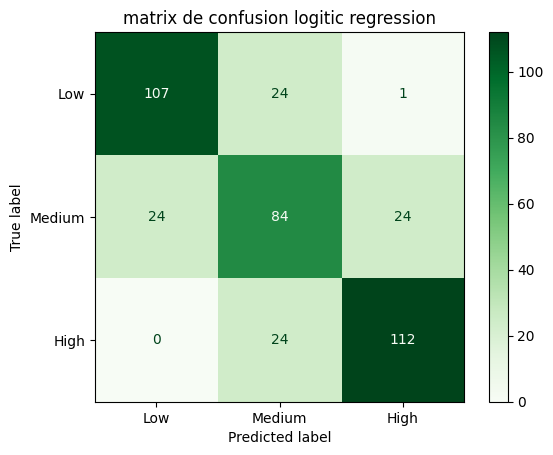

In [41]:
from sklearn.metrics import ConfusionMatrixDisplay


ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["Low", "Medium", "High"],
    display_labels=["Low", "Medium", "High"],
    cmap="Greens"
)

plt.title("matrix de confusion logitic regression")
plt.show()

# model final

In [ ]:
from sklearn.linear_model import LogisticRegression

def train_logistic_regression():

    preprocessor = get_preprocessor()

    logistic_model = LogisticRegression(max_iter=1000)

    pipeline = get_pipeline(logistic_model, preprocessor)

    param = {
        "classifier__C": [0.01, 0.1, 1, 10, 100]
    }

    grid_search_lr = train_model(pipeline, param)

    best_model_lr = grid_search_lr.best_estimator_

In [ ]:
best_model_lr = train_logistic_regression()

print("Best parameters:", model.best_params_)

print("Best F1 macro:", model.best_score_)

In [ ]:
# import joblib
# joblib.dump(
#     best_model_lr,
#     "logistic_regression_pipeline.joblib"
# )

In [ ]:
# best_model_lr = joblib.load(
#     "logistic_regression_pipeline.joblib"
# )